### Практическое задание №3. Классификация мест залежей нефти и газа
Максимальный балл за задание: 12 баллов.

Нефтегазовая отрасль имеет сложную технологическую цепочку, которая начинается с геологической разведки и заканчивается доставкой нефти и газа потребителям. Одной из важных задач является определение места залежей — на суше или в море — на основе различных параметров.

Ваша задача: разработать алгоритм машинного обучения, который позволит классифицировать место залежей нефти и газа.

### Критерии оценивания
Анализ данных и их предобработка  -	0-3 балла

Feature Engineering и отбор признаков	 -  0-2 балла

Выбор и обучение нескольких моделей	-  0-3 балла

Подбор гиперпараметров и объяснение выбора лучшей модели -	0-2 балла

Результат на Kaggle -	0-1 балл

Качество оформления ноутбука (чистый код, комментарии, выводы)	- 0-1 балл

Итого	- 12 баллов

### Что нужно сделать
1. Принять участие в соревновании на Kaggle:

2. Разработать и оформить решение в ноутбуке:

2.1 Исследование и анализ датасета.

2.2. Предобработка данных.

2.3. Feature Engineering (если необходимо).

2.4. Подбор признаков, их анализ и оценка важности.

2.5. Обучение нескольких моделей, их сравнение.

2.6. Подбор гиперпараметров.

2.7. Выбор лучшей модели и объяснение выбора.

2.8. Предсказание на тестовых данных.

3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.

4. Прикрепить ноутбук (.ipynb) с решением на платформу.

Требования к ноутбуку:

Комментарии и пояснения к коду.

Выводы к каждому этапу (анализ данных, предобработка, обучение).

Код должен быть чистым и читаемым.

In [362]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, MultiLabelBinarizer, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


### 2.1 Исследование и анализ датасета.

In [ ]:
# Загружаем тренировочный датасет
file_path = r"C:\IDE\2 семестр\Классическое МО\data\classification-of-oil-and-gas\train_oil.csv" 
train_oil = pd.read_csv(file_path, sep=',')

In [ ]:

# Загружаем тестовый датасет
file_path1 = r"C:\IDE\2 семестр\Классическое МО\data\classification-of-oil-and-gas\oil_test.csv" 
test_oil = pd.read_csv(file_path1, sep=',')


In [259]:
#Ознакамливаемся с датасетом
train_oil.head()

,Field name,Reservoir unit,Country,Region,Basin name,Tectonic regime,Latitude,Longitude,Operator company,Onshore/Offshore,Hydrocarbon type,Reservoir status,Structural setting,Depth,Reservoir period,Lithology,Thickness (gross average ft),Thickness (net pay average ft),Porosity,Permeability
0,ZHIRNOV,MELEKESKIAN,RUSSIA,FORMER SOVIET UNION,VOLGA-URAL,COMPRESSION/EVAPORITE,51.0000,44.8042,NIZHNEVOLZHSKNET,ONSHORE,OIL,DECLINING PRODUCTION,FORELAND,1870,CARBONIFEROUS,SANDSTONE,262.0,33.0,24.0,30.0
1,LAGOA PARDA,LAGOA PARDA (URUCUTUCA),BRAZIL,LATIN AMERICA,ESPIRITO SANTO,EXTENSION,-19.6017,-39.8332,PETROBRAS,ONSHORE,OIL,NEARLY DEPLETED,PASSIVE MARGIN,4843,PALEOGENE,SANDSTONE,2133.0,72.0,23.0,350.0
2,ABQAIQ,ARAB D,SAUDI ARABIA,MIDDLE EAST,THE GULF,COMPRESSION/EVAPORITE,26.0800,49.8100,SAUDI ARAMCO,ONSHORE,OIL,REJUVENATING,FORELAND,6050,JURASSIC,LIMESTONE,250.0,184.0,21.0,410.0
3,MURCHISON,BRENT,UK /NORWAY,EUROPE,NORTH SEA NORTHERN,EXTENSION,61.3833,1.7500,CNR,OFFSHORE,OIL,NEARLY DEPLETED,RIFT,8988,JURASSIC,SANDSTONE,425.0,300.0,22.0,750.0
4,WEST PEMBINA,NISKU (PEMBINA L POOL),CANADA,NORTH AMERICA,WESTERN CANADA,COMPRESSION,53.2287,-115.8008,NUMEROUS,ONSHORE,OIL,UNKNOWN,FORELAND,9306,DEVONIAN,DOLOMITE,233.0,167.0,11.8,1407.0


In [260]:
#Проверяем типы данных и наличие пропусков
train_oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Field name                      309 non-null    object 
 1   Reservoir unit                  309 non-null    object 
 2   Country                         282 non-null    object 
 3   Region                          271 non-null    object 
 4   Basin name                      271 non-null    object 
 5   Tectonic regime                 309 non-null    object 
 6   Latitude                        282 non-null    float64
 7   Longitude                       279 non-null    float64
 8   Operator company                309 non-null    object 
 9   Onshore/Offshore                309 non-null    object 
 10  Hydrocarbon type                309 non-null    object 
 11  Reservoir status                309 non-null    object 
 12  Structural setting              309 

In [261]:
#Отображаем баланс классов целевой переменной тренировочного датасета
train_oil['Onshore/Offshore'].value_counts()

Onshore/Offshore
ONSHORE             218
OFFSHORE             86
ONSHORE-OFFSHORE      5
Name: count, dtype: int64

C:\Users\troyd\AppData\Local\Temp\ipykernel_13560\4231111981.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x ='Onshore/Offshore', data = train_oil, palette='hls')


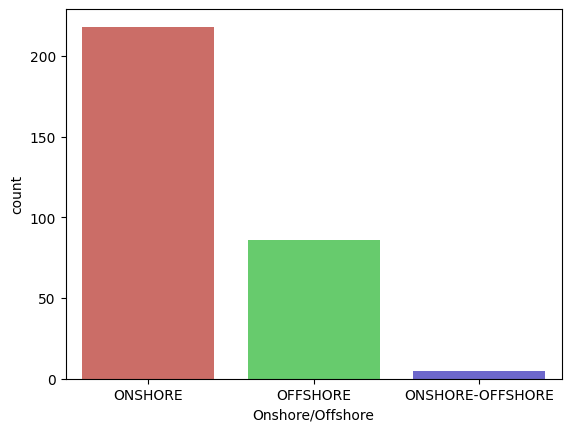

In [262]:
#Отображаем баланс классов целевой переменной тренировочного датасета
sns.countplot(x ='Onshore/Offshore', data = train_oil, palette='hls')
plt.show()

Вывод:

Классы неравномерны, преобладает класс ONSHORE, что может негативно повлиять на модель классификации, возможно необходимо применить балансировку классов.
Также отсутствует часть данных в стобцах Country Region,  Basin name, Latitude, Longitude. Столбцы   Country Region,  Basin name, по моему мнению, являются неинформативными и подлежат удалению, поэтому пропуски в них не нужно обрабатывать. Столбцы Latitude, Longitude напрямую связаны с целевой переменной, так как от их значений зависит расположение (onshore/offshore) месторождений. Поэтому удалять строки с пустыми значениями опасно, так как может привести к потере даных. Поэтому данные пропуски необходимо заполнить некоторыми значениями.

### 2.2. Предобработка данных.

In [ ]:
# Создаем копии датасетов
train_oil_copy = train_oil.copy()
test_oil_copy = test_oil.copy()

In [ ]:
# Удаляем неинформативные признаки
train_oil_copy = train_oil_copy.drop(['Field name', 'Reservoir unit', 'Country', 'Region', 'Basin name',
       'Operator company'], axis=1)
test_oil_copy = test_oil_copy.drop(['Field name', 'Reservoir unit', 'Country', 'Region', 'Basin name',
       'Operator company'], axis=1)

In [265]:
train_oil_copy.describe()

,Latitude,Longitude,Depth,Thickness (gross average ft),Thickness (net pay average ft),Porosity,Permeability
count,282.00000,279.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,35.62426,-12.508435,6755.669903,760.087379,183.683236,17.825178,476.994757
std,22.19116,86.387220,3628.094135,1353.934404,282.252489,7.171048,1000.140605
min,-38.39890,-151.615300,220.000000,11.000000,2.120000,1.100000,0.010000
25%,28.24915,-102.336500,4059.000000,128.000000,45.000000,12.000000,10.000000
50%,38.13500,1.810000,6500.000000,312.000000,110.000000,17.000000,68.000000
75%,52.13360,56.179900,9186.000000,715.000000,205.000000,23.600000,390.000000
max,76.44620,148.417000,19888.000000,8200.000000,2976.000000,35.000000,7500.000000


In [ ]:
#Обработка пустых значений
# индикаторы пропусков
train_oil_copy["Latitude_missing"] = train_oil_copy["Latitude"].isna().astype(int)
train_oil_copy["Longitude_missing"] = train_oil_copy["Longitude"].isna().astype(int)

# заполнение пропусков
train_oil_copy["Latitude"] = train_oil_copy["Latitude"].fillna(train_oil_copy["Latitude"].median())
train_oil_copy["Longitude"] = train_oil_copy["Longitude"].fillna(train_oil_copy["Longitude"].median())

# индикаторы пропусков
test_oil_copy["Latitude_missing"] = test_oil_copy["Latitude"].isna().astype(int)
test_oil_copy["Longitude_missing"] = test_oil_copy["Longitude"].isna().astype(int)

# заполнение пропусков
test_oil_copy["Latitude"] = test_oil_copy["Latitude"].fillna(test_oil_copy["Latitude"].median())
test_oil_copy["Longitude"] = test_oil_copy["Longitude"].fillna(test_oil_copy["Longitude"].median())

In [268]:
train_oil_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Tectonic regime                 309 non-null    object 
 1   Latitude                        309 non-null    float64
 2   Longitude                       309 non-null    float64
 3   Onshore/Offshore                309 non-null    object 
 4   Hydrocarbon type                309 non-null    object 
 5   Reservoir status                309 non-null    object 
 6   Structural setting              309 non-null    object 
 7   Depth                           309 non-null    int64  
 8   Reservoir period                309 non-null    object 
 9   Lithology                       309 non-null    object 
 10  Thickness (gross average ft)    309 non-null    float64
 11  Thickness (net pay average ft)  309 non-null    float64
 12  Porosity                        309 

Вывод:

В данном разделе были удалены неинформативные признаки, также проанлизированны числовые признаки. Видно, что в некоторых признаках присутствуют значения, потенциально возможные выбросы. Не стал их удалять т.к. семплов мало, есть шанс потерять данные, а также т.к. алгоритмы классификации, основанные на деревьях решений, которые я планирую использовать, не сильно чувствительны к выбросам.

Также были обработаны пропуски в стобцах Latitude, Longitude. Были добавлены дополнительные признаки, указывающие модели, на пропущенные значения в изначальных столбцах. Сами пропуски были заполнены медианными значениями.

### 2.3. Feature Engineering

In [ ]:
# Кодируем целевую переменную
label_encoder = LabelEncoder()
label_encoder.fit(train_oil_copy['Onshore/Offshore'])
train_oil_copy['Onshore/Offshore'] = label_encoder.transform(train_oil_copy['Onshore/Offshore'])


In [ ]:
# Кодируем категориальные признаки
ordinal_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value', 
    unknown_value=-1
)
train_oil_copy[['Hydrocarbon type', 'Reservoir status', 'Reservoir period', 'Lithology']] = ordinal_encoder.fit_transform(train_oil_copy[['Hydrocarbon type', 'Reservoir status', 'Reservoir period', 'Lithology']])
test_oil_copy[['Hydrocarbon type', 'Reservoir status', 'Reservoir period', 'Lithology']] = ordinal_encoder.transform(test_oil_copy[['Hydrocarbon type', 'Reservoir status', 'Reservoir period', 'Lithology']])

In [271]:
# Подготавливаем множественные категориальные признаки к кодировке
train_oil_copy['Structural setting'] = train_oil_copy['Structural setting'].str.split('/')
test_oil_copy['Structural setting'] = test_oil_copy['Structural setting'].str.split('/')
train_oil_copy['Structural setting']

0            [FORELAND]
1      [PASSIVE MARGIN]
2            [FORELAND]
3                [RIFT]
4            [FORELAND]
             ...       
304            [THRUST]
305          [FORELAND]
306          [FORELAND]
307          [FORELAND]
308          [FORELAND]
Name: Structural setting, Length: 309, dtype: object

In [272]:
# Подготавливаем множественные категориальные признаки к кодировке
train_oil_copy['Tectonic regime'] = train_oil_copy['Tectonic regime'].str.split('/')
test_oil_copy['Tectonic regime'] = test_oil_copy['Tectonic regime'].str.split('/')
train_oil_copy['Tectonic regime']

0                         [COMPRESSION, EVAPORITE]
1                                      [EXTENSION]
2                         [COMPRESSION, EVAPORITE]
3                                      [EXTENSION]
4                                    [COMPRESSION]
                          ...                     
304                                  [COMPRESSION]
305    [COMPRESSION, EVAPORITE, EXTENSION, LINKED]
306                                  [COMPRESSION]
307                                  [COMPRESSION]
308                                  [COMPRESSION]
Name: Tectonic regime, Length: 309, dtype: object

In [ ]:
#Кодируем категориальные признаки
mlb = MultiLabelBinarizer()
Tectonic_regime_encoded_train = mlb.fit_transform(train_oil_copy['Tectonic regime'])
Tectonic_regime_encoded_test = mlb.transform(test_oil_copy['Tectonic regime'])

In [274]:
#Кодируем категориальные признаки
mlb1 = MultiLabelBinarizer()
Structural_setting_encoded_train = mlb1.fit_transform(train_oil_copy['Structural setting'])
Structural_setting_encoded_test = mlb1.transform(test_oil_copy['Structural setting'])

c:\Users\troyd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:1007: UserWarning: unknown class(es) [''] will be ignored
  warnings.warn(


In [ ]:
#Подготавливаем закодированные признаки для объединения с датасетами
Structural_setting_encoded_train_df = pd.DataFrame(Structural_setting_encoded_train, columns=mlb1.classes_)
Structural_setting_encoded_test_df = pd.DataFrame(Structural_setting_encoded_test, columns=mlb1.classes_)

In [ ]:
#Подготавливаем закодированные признаки для объединения с датасетами
Tectonic_regime_encoded_train_df = pd.DataFrame(Tectonic_regime_encoded_train, columns=mlb.classes_)
Tectonic_regime_encoded_test_df = pd.DataFrame(Tectonic_regime_encoded_test, columns=mlb.classes_)


In [ ]:
#Объединяем закодированные признаки с изначальными датасетами
train_oil_copy = pd.concat([train_oil_copy, Tectonic_regime_encoded_train_df], axis=1)
test_oil_copy = pd.concat([test_oil_copy, Tectonic_regime_encoded_test_df], axis=1)

In [ ]:
#Объединяем закодированные признаки с изначальными датасетами
train_oil_copy = pd.concat([train_oil_copy, Structural_setting_encoded_train_df], axis=1)
test_oil_copy = pd.concat([test_oil_copy, Structural_setting_encoded_test_df], axis=1)

In [ ]:
# Удаляем изначальные признаки
train_oil_copy = train_oil_copy.drop(['Tectonic regime', 'Structural setting'], axis = 1)
test_oil_copy = test_oil_copy.drop(['Tectonic regime', 'Structural setting'], axis = 1)

In [280]:
test_oil_copy.head()

,Latitude,Longitude,Hydrocarbon type,Reservoir status,Depth,Reservoir period,Lithology,Thickness (gross average ft),Thickness (net pay average ft),Porosity,...,FORELAND,INTRACRATONIC,INVERSION,PASSIVE MARGIN,RIFT,SALT,SUB-SALT,SUB-THRUST,THRUST,WRENCH
0,29.7422,28.4925,2.0,5.0,10282,4.0,7.0,745.0,144.0,10.0,...,0,0,0,0,1,0,0,0,0,0
1,31.4382,31.3616,1.0,2.0,10499,12.0,7.0,509.0,410.0,20.0,...,0,0,0,0,0,0,0,0,0,1
2,48.4740,57.6667,3.0,4.0,6000,2.0,5.0,300.0,105.0,10.0,...,1,0,0,0,0,0,1,0,0,0
3,60.7833,1.7333,3.0,6.0,9790,9.0,7.0,886.0,344.0,17.0,...,0,0,0,0,1,0,0,0,0,0
4,21.6000,72.9167,3.0,5.0,2950,14.0,7.0,670.0,0.0,21.0,...,0,0,0,0,1,0,0,0,0,1


Вывод:

В данном разделе были закодированны целевая переменная, а такжн категориальные признаки.

### 2.4. Подбор признаков, их анализ и оценка важности.



In [281]:
X_train = train_oil_copy.drop(columns='Onshore/Offshore')
X_test = test_oil_copy
y_train = train_oil_copy['Onshore/Offshore']

Вывод:
Признаки ['Field name', 'Reservoir unit', 'Country', 'Region', 'Basin name','Operator company'] были удалены, т.к., по моему мнению, являются слишком индивидуальными и не могут дать необходимой информации для классификации месторождений. Оставшиеся признаки были подготовленны и выбраны для классификации.


### 2.5. Обучение нескольких моделей, их сравнение.

In [347]:
# Создаем модель DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

# Обучаем на данных
tree.fit(X_train, y_train)

# Делаем предсказание
y_pred_DT = tree.predict(X_test)

'''Score 0.81632'''


'Score 0.80994'

In [351]:
# Создаем модель RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

# Обучаем
rf.fit(X_train, y_train)

# Делаем предсказание
y_pred_RF = rf.predict(X_test)

'''Score 0.89653'''

'Score 0.89653'

In [ ]:
# Создаем модель GradientBoostingClassifier

GDC = GradientBoostingClassifier(random_state=42)

# Обучаем
GDC.fit(X_train, y_train)

# Делаем предсказание
y_pred_GDC = GDC.predict(X_test)

'''Score 0.81364'''

Выводы: 

Были обучены модели DecisionTreeClassifier, RandomForestClassifier, GradientBoostingClassifier а также сделаны предсказания на тестовых данных. Для воспроизводимости результатов использован фиксированный random_state.

Наилучший результат показала модель RandomForestClassifier Score 0.89653

### 2.6. Подбор гиперпараметров.

In [ ]:
# Создаем модель DecisionTreeClassifier с параметром class_weight='balanced'

tree_class_weight = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# Обучаем на данных (X — признаки, y — цель)
tree_class_weight.fit(X_train, y_train)

# Делаем предсказание
y_pred_DT_CW = tree_class_weight.predict(X_test)

'''Score 0.83160'''

In [ ]:
# Создаем модель RandomForestClassifier с параметром class_weight='balanced'

rf_class_weight = RandomForestClassifier(class_weight='balanced', random_state=42)

# Обучаем
rf_class_weight.fit(X_train, y_train)

# Делаем предсказание
y_pred_RF_CW = rf_class_weight.predict(X_test)

'''Score 0.81364'''

In [375]:
# Подбор параметров для DecisionTreeClassifier с помощью GridSearchCV

dtree = DecisionTreeClassifier(random_state=42)
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 4, 5, 6],
    'min_samples_split': [5, 6, 7, 8, 9, 10, 11],
    'min_samples_leaf': [1, 2, 3],
    'class_weight': [None, 'balanced']
}

# Настраиваем поиск (5-фолдовая кросс-валидация)
grid_search = GridSearchCV(estimator=dtree, param_grid=param_grid, cv=5, scoring='f1_weighted')

# Обучаем
grid_search.fit(X_train, y_train)

# Результаты
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая точность: {grid_search.best_score_:.4f}")

# Используем лучшую модель
best_model = grid_search.best_estimator_

Лучшие параметры: {'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 8}
Лучшая точность: 0.8226


In [ ]:
y_pred_DT_GS = best_model.predict(X_test)

'''Score 0.79634'''

In [377]:
submission = pd.DataFrame({
    "index": range(len(y_pred_DT_GS)),
    "Onshore/Offshore": y_pred_DT_GS
})
submission.to_csv("submission.csv", index=False)

In [378]:
# Подбор параметров для RandomForestClassifier с помощью RandomizedSearchCV

rf_RS = RandomForestClassifier(random_state=42)

param_dist = {
    'n_estimators': [90, 100, 110],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False] 
}



# n_iter=50 проверит только 50 случайных комбинаций
random_search = RandomizedSearchCV(rf_RS, param_distributions=param_dist, 
                                   n_iter=50, cv=5, scoring='f1_weighted', n_jobs=-1)

random_search.fit(X_train, y_train)
print(random_search.best_params_)

{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10, 'bootstrap': False}


In [379]:
# Используем лучшую модель
best_model_RFC= random_search.best_estimator_
y_pred_RFS_RSCV = best_model_RFC.predict(X_test)

In [ ]:
gbc = GradientBoostingClassifier(random_state=42)

# 3. Определение сетки параметров (Grid)
# Мы указываем списки значений, которые хотим протестировать
param_grid1 = {
    'learning_rate': [0.01, 0.1, 0.2],    # Скорость обучения
    'n_estimators': [50, 100, 150],      # Количество деревьев
    'max_depth': [2, 3, 4],               # Глубина каждого дерева
    'subsample': [0.8, 1.0, 1.2]               # Доля выборки для обучения каждого дерева
}

# 4. Настройка GridSearchCV
grid_search1 = GridSearchCV(
    estimator=gbc,
    param_grid=param_grid1,
    scoring='f1_weighted',  # Метрика качества
    cv=5,                # 5-кратная кросс-валидация
    n_jobs=-1            # Использовать все доступные ядра процессора для ускорения
)

# 5. Запуск поиска лучших параметров
grid_search1.fit(X_train, y_train)

# 6. Вывод результатов
print(f"Лучшие параметры: {grid_search1.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search1.best_score_:.4f}")

In [ ]:
best_model_GBC= grid_search1.best_estimator_
y_pred_GBC_GS = best_model_GBC.predict(X_test)

'''Score 0.84759'''

Выводы:

Были обучены модели DecisionTreeClassifier, RandomForestClassifier с параметром class_weight='balanced' для корректировки разбалансированности классов, метрики моделей составили '''Score 0.83160''', '''Score 0.81364''' соответственно. 

Также с помощью методов GridSearchCV были подобраны параметры для моделей DecisionTreeClassifier, GradientBoostingClassifier hезультаты '''Score 0.79634''', '''Score 0.84759''' соответственно.

С помощью RandomizedSearchCV подобраны параметры для модели RandomForestClassifier  результаты '''Score 0.87251'''.

Наилучшие результаты из представленных показал алгоритм RandomForestClassifier. Его результаты с параметрами по умолчанию Score 0.89653, с подообранными параметрами Score 0.87251. Преимущество RandomForestClassifier в устойчивости к переобучению по сравнению с DecisionTreeClassifier.

### 3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.

![alt text](<Снимок экрана 2026-03-13 185949.png>)

### EXAMPLE

In [387]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
train = pd.read_csv(r"C:\IDE\2 семестр\Классическое МО\data\classification-of-oil-and-gas\train_oil.csv" )
test = pd.read_csv(r"C:\IDE\2 семестр\Классическое МО\data\classification-of-oil-and-gas\oil_test.csv")

# Выводим форму датасетов, чтобы понять количество строк и столбцов
print(f"Train dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")

Train dataset shape: (309, 20)
Test dataset shape: (133, 19)


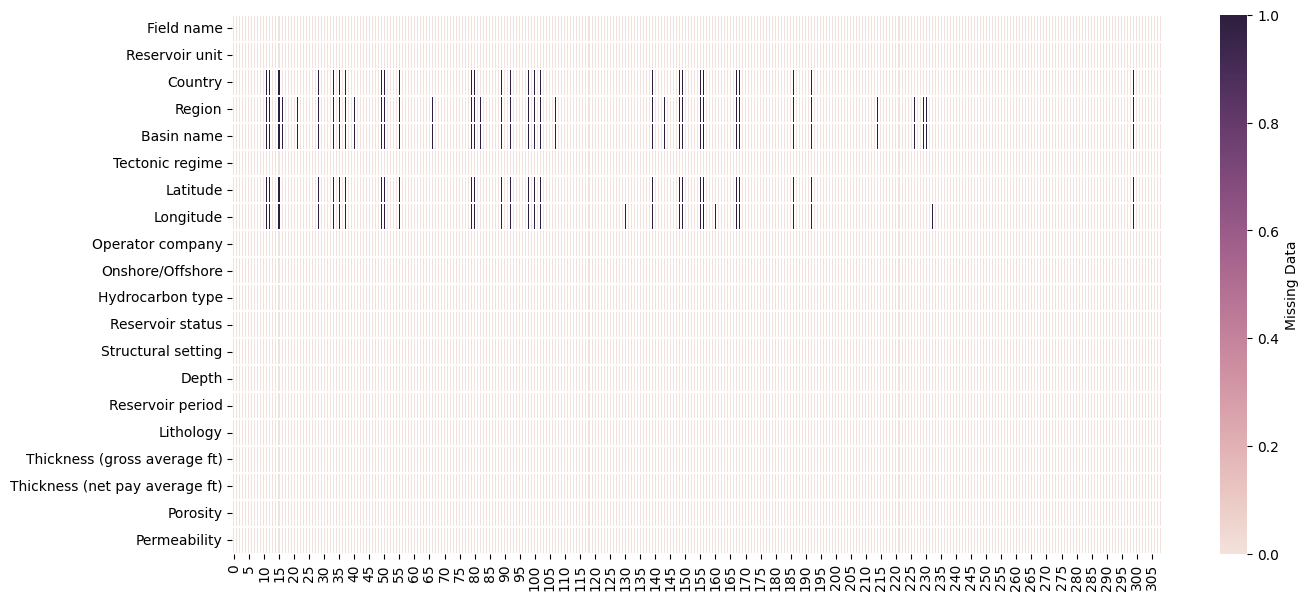

In [388]:
'''Визуализируем пропуски в данных с помощью тепловой карты, чтобы наглядно увидеть, в каких столбцах и строках отсутствуют значения:
'''
plt.figure(figsize=(15,7))

cmap = sns.cubehelix_palette(as_cmap=True, light=.9)

sns.heatmap(train.isna().transpose(), cmap=cmap,
            cbar_kws={'label': 'Missing Data'}, linewidths=0.05)

plt.savefig("visualizing_missing_data_with_heatmap_Seaborn_Python.png", dpi=100)

In [389]:
train = train.dropna()

C:\Users\troyd\AppData\Local\Temp\ipykernel_13560\2665399700.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Onshore/Offshore', data=y_data, palette='hls')


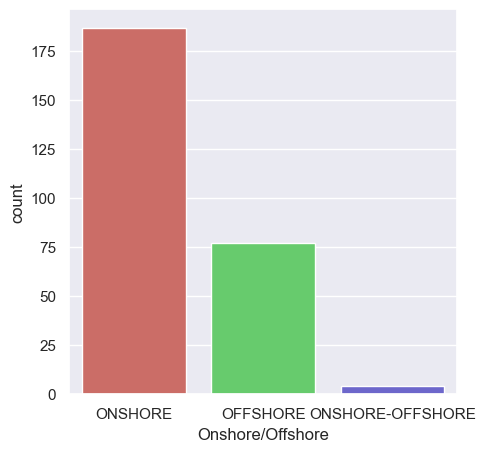

In [390]:
sns.set(rc = {'figure.figsize':(5,5)})
y_data = pd.DataFrame(train['Onshore/Offshore'])
sns.countplot(x='Onshore/Offshore', data=y_data, palette='hls')
plt.show()

In [391]:
train['Tectonic regime'].value_counts()

Tectonic regime
COMPRESSION                                                 57
EXTENSION                                                   26
COMPRESSION/EROSION                                         25
COMPRESSION/EVAPORITE                                       18
INVERSION/COMPRESSION/EXTENSION                             17
EXTENSION/EROSION                                           12
GRAVITY/EXTENSION/EVAPORITE                                 10
INVERSION/COMPRESSION/EXTENSION/EROSION                      7
GRAVITY/EXTENSION/EVAPORITE/SYNSEDIMENTATION                 7
COMPRESSION/EVAPORITE/EXTENSION/LINKED                       7
INVERSION/STRIKE-SLIP/TRANSPRESSION/EXTENSION/BASEMENT-I     5
COMPRESSION/EXTENSION/LINKED                                 4
GRAVITY/EVAPORITE/EXTENSION                                  4
INVERSION/COMPRESSION/EXTENSION/EVAPORITE                    4
GRAVITY/EVAPORITE/COMPRESSION                                4
COMPRESSION/EXTENSION/EVAPORITE        

In [392]:
# Удаление ненужных признаков, чтобы упростить базовую модель
# Здесь мы удаляем текстовые и сложные категориальные признаки, которые потребовали бы сложной обработки

train = train.drop(columns=['Tectonic regime', 'Structural setting', 'Field name', 'Reservoir unit', 'Country',                          'Region', 'Basin name', 'Operator company'])

test = test.drop(columns=['Tectonic regime', 'Structural setting', 'Field name', 'Reservoir unit', 'Country',                          'Region', 'Basin name', 'Operator company'])

In [393]:
'''Остальные категориальные признаки закодируем с помощью OrdinalEncoder. Это позволит преобразовать текстовые категории в числовые значения и учесть, категории, которые модель не видела на этапе обучения, но они оказались и в test:
'''
from sklearn.preprocessing import OrdinalEncoder

# Список категориальных столбцов, которые нужно закодировать
categ = ['Hydrocarbon type', 'Reservoir status', 'Reservoir period', 'Lithology']

# Создаем OrdinalEncoder, который заменит категории числами
# Если в тестовой выборке появятся неизвестные категории, они будут заменены на -1
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Обучаем encoder на тренировочных данных и сразу трансформируем train и test
train_encoded = encoder.fit_transform(train[categ])
test_encoded = encoder.transform(test[categ])

# Заменяем старые категориальные столбцы новыми закодированными
train[categ] = train_encoded
test[categ] = test_encoded

<Axes: >

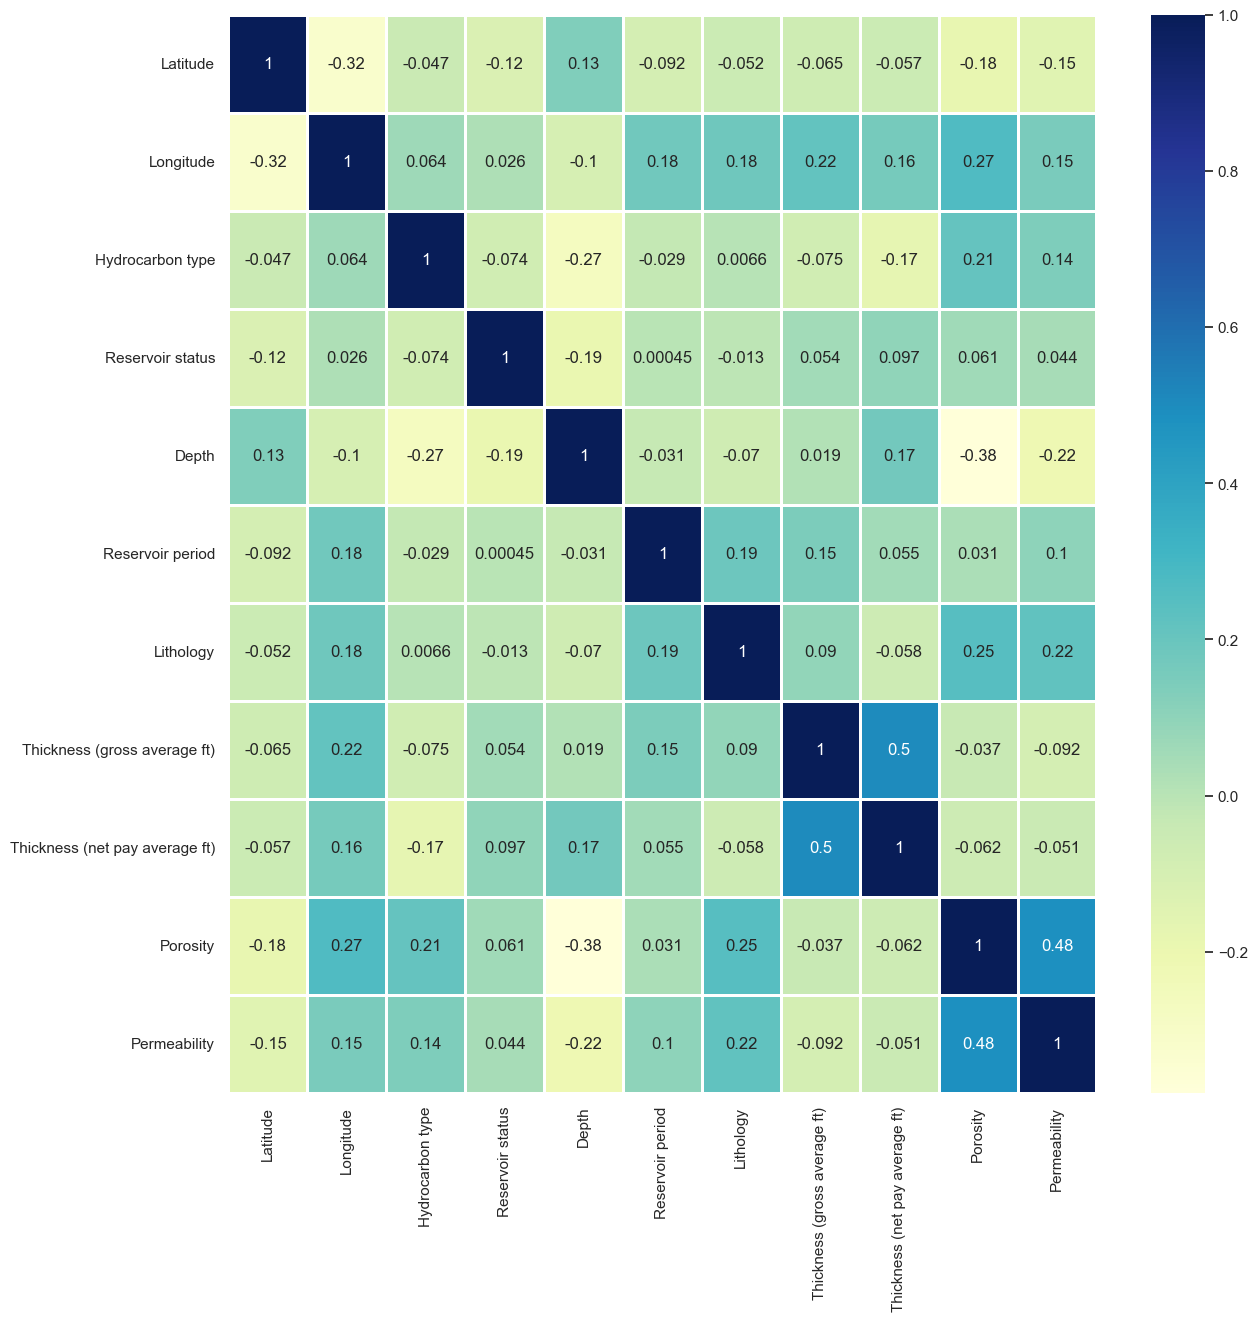

In [394]:
sns.set(rc = {'figure.figsize':(14, 14)})

sns.heatmap(train.corr(numeric_only=True), annot=True, cmap="YlGnBu", linecolor='white', linewidths=1)

In [395]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=['Onshore/Offshore'])
y = train['Onshore/Offshore']

# Разбиваем данные с учетом стратификации
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,           # 20% данных в тест
    random_state=42,         # Фиксируем для воспроизводимости
    stratify=y               # Стратифицированное разбиение
)

print(f'Train dataset size: {X_train.shape}, {y_train.shape}')
print(f'Train dataset size: {X_test.shape}, {y_test.shape}')

Train dataset size: (214, 11), (214,)
Train dataset size: (54, 11), (54,)


In [396]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Создадим модель дерева решений
tree = DecisionTreeClassifier()
knn = KNeighborsClassifier(2)

# обучение модели
tree.fit(X_train, y_train)
knn.fit(X_train, y_train)

# предсказание ответов для тестовой выборки
y_pred_tree = tree.predict(X_test)
y_pred_knn = knn.predict(X_test)

In [397]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# answers_pred - ответы которые вернула модель для X_test
# y_test - это правильные ответы для X_test
print(f'Accuracy: {accuracy_score(y_test, y_pred_tree)}')
print(f'Accuracy: {accuracy_score(y_test, y_pred_knn)}')

Accuracy: 0.8333333333333334
Accuracy: 0.6111111111111112


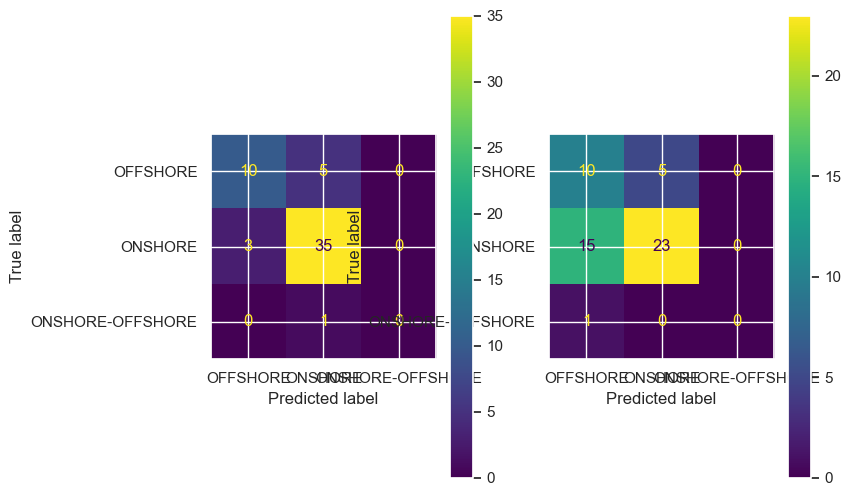

In [398]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

conf_matrix_tree = confusion_matrix(y_test, y_pred_tree)
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)

fig, axes = plt.subplots(1, 2, figsize=(8,6), dpi=100)

display = ConfusionMatrixDisplay(conf_matrix_tree, display_labels=tree.classes_)
display.plot(ax=axes[0])

display = ConfusionMatrixDisplay(conf_matrix_knn, display_labels=knn.classes_)
display.plot(ax=axes[1])

In [399]:
y_test_pred = tree.predict(test)
ans_df = pd.DataFrame(y_test_pred, columns=['Onshore/Offshore '])

ans_df.reset_index(inplace=True)
ans_df.to_csv('submition.csv', index=False)